# Proyek Klasifikasi Gambar: Animals-10 Dataset
- **Nama:** Ilham Jaya Saputra
- **Email:** jayailham04@gmail.com
- **ID Dicoding:** Ilhamjayas

## Deskripsi Proyek
Proyek ini melakukan klasifikasi gambar menggunakan dataset **Animals-10** dari Kaggle  
yang berisi **±26.000 gambar** hewan dari **10 kelas** berbeda.  
Model dibangun menggunakan **MobileNetV2** (pretrained ImageNet) sebagai backbone, dibungkus dalam arsitektur **Sequential** dengan **Conv2D** dan **Pooling Layer** tambahan — memenuhi Kriteria 4 Dicoding.

| Kelas | Kelas | Kelas | Kelas | Kelas |
|-------|-------|-------|-------|-------|
| dog | cat | horse | spider | butterfly |
| chicken | sheep | cow | squirrel | elephant |


## 1. Import Library


In [1]:
# ================================================================
# IMPORT SEMUA LIBRARY
# ================================================================
import os
import shutil
import zipfile
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

# TensorFlow & Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, GlobalAveragePooling2D,
    Dense, Dropout, BatchNormalization
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau,
    ModelCheckpoint
)
from tensorflow.keras.optimizers import Adam

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report

from PIL import Image

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f'TensorFlow : {tf.__version__}')
print(f'Keras      : {getattr(keras, "__version__", "bundled with TensorFlow")}')
print(f'GPU        : {tf.config.list_physical_devices("GPU")}')

# Jangan gunakan history/checkpoint/hasil evaluasi sesi sebelumnya.
TRAINING_COMPLETED = False
EVALUATION_COMPLETED = False
EXPORT_COMPLETED = False
history = None
best_model = None


TensorFlow : 2.21.0
Keras      : 3.13.2
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data Loading
### 2.1 Setup Kaggle API & Download Dataset
Unggah `kaggle.json` melalui dialog. Isi kredensial tidak ditulis ke kode maupun output notebook.


In [2]:
from google.colab import files
from pathlib import Path
import json
import subprocess
import sys
import hashlib
import uuid
import re
from datetime import datetime, timezone

# Instal hanya Kaggle CLI, tanpa mengganti TensorFlow yang sedang dipakai.
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'kaggle'], check=True)
print('Unggah kaggle.json dari akun Kaggle Anda.')
uploaded_credentials = files.upload()
if 'kaggle.json' not in uploaded_credentials:
    raise FileNotFoundError('kaggle.json belum diunggah.')


Unggah kaggle.json dari akun Kaggle Anda.


Saving kaggle.json to kaggle.json


In [3]:
kaggle_dir = Path.home() / '.kaggle'
kaggle_dir.mkdir(parents=True, exist_ok=True)
credential_path = kaggle_dir / 'kaggle.json'
credential_path.write_bytes(uploaded_credentials['kaggle.json'])
credential_path.chmod(0o600)
del uploaded_credentials
print('Kaggle API siap; isi kredensial tidak ditampilkan.')


Kaggle API siap; isi kredensial tidak ditampilkan.


In [4]:
subprocess.run([
    'kaggle', 'datasets', 'download', '-d', 'alessiocorrado99/animals10',
    '-p', '/content'
], check=True)
EXTRACT_DIR = '/content/animals10'
with zipfile.ZipFile('/content/animals10.zip', 'r') as z:
    z.extractall(EXTRACT_DIR)
print('Ekstraksi selesai!')
print(os.listdir(EXTRACT_DIR))


Ekstraksi selesai!
['translate.py', 'raw-img']


### 2.2 Eksplorasi Dataset


In [5]:
RAW_DATA_DIR = '/content/animals10/raw-img'

TRANSLATE = {
    'cane'      : 'dog',
    'cavallo'   : 'horse',
    'elefante'  : 'elephant',
    'farfalla'  : 'butterfly',
    'gallina'   : 'chicken',
    'gatto'     : 'cat',
    'mucca'     : 'cow',
    'pecora'    : 'sheep',
    'ragno'     : 'spider',
    'scoiattolo': 'squirrel',
}

VALID_EXT = ('.jpg', '.jpeg', '.png', '.gif', '.JPG', '.JPEG', '.PNG')

filepaths, labels = [], []
class_counts = {}

print(f"{'Kelas':<15} {'Jumlah Gambar':>15}")
print('-' * 32)
for folder_it, folder_en in TRANSLATE.items():
    folder_path = os.path.join(RAW_DATA_DIR, folder_it)
    if not os.path.exists(folder_path):
        continue
    imgs = [f for f in sorted(os.listdir(folder_path)) if f.lower().endswith(VALID_EXT)]
    for img in imgs:
        filepaths.append(os.path.join(folder_path, img))
        labels.append(folder_en)
    class_counts[folder_en] = len(imgs)
    print(f"{folder_en:<15} {len(imgs):>15,}")

print('-' * 32)
print(f"{'TOTAL':<15} {len(filepaths):>15,}")

# Simpan ke DataFrame
df = pd.DataFrame({'filepath': filepaths, 'label': labels})
print(f'\nShape DataFrame: {df.shape}')
df.head()

assert len(df) >= 1000 and df['label'].nunique() == 10, 'Dataset belum lengkap.'


Kelas             Jumlah Gambar
--------------------------------
dog                       4,863
horse                     2,623
elephant                  1,446
butterfly                 2,112
chicken                   3,098
cat                       1,668
cow                       1,866
sheep                     1,820
spider                    4,821
squirrel                  1,862
--------------------------------
TOTAL                    26,179

Shape DataFrame: (26179, 2)


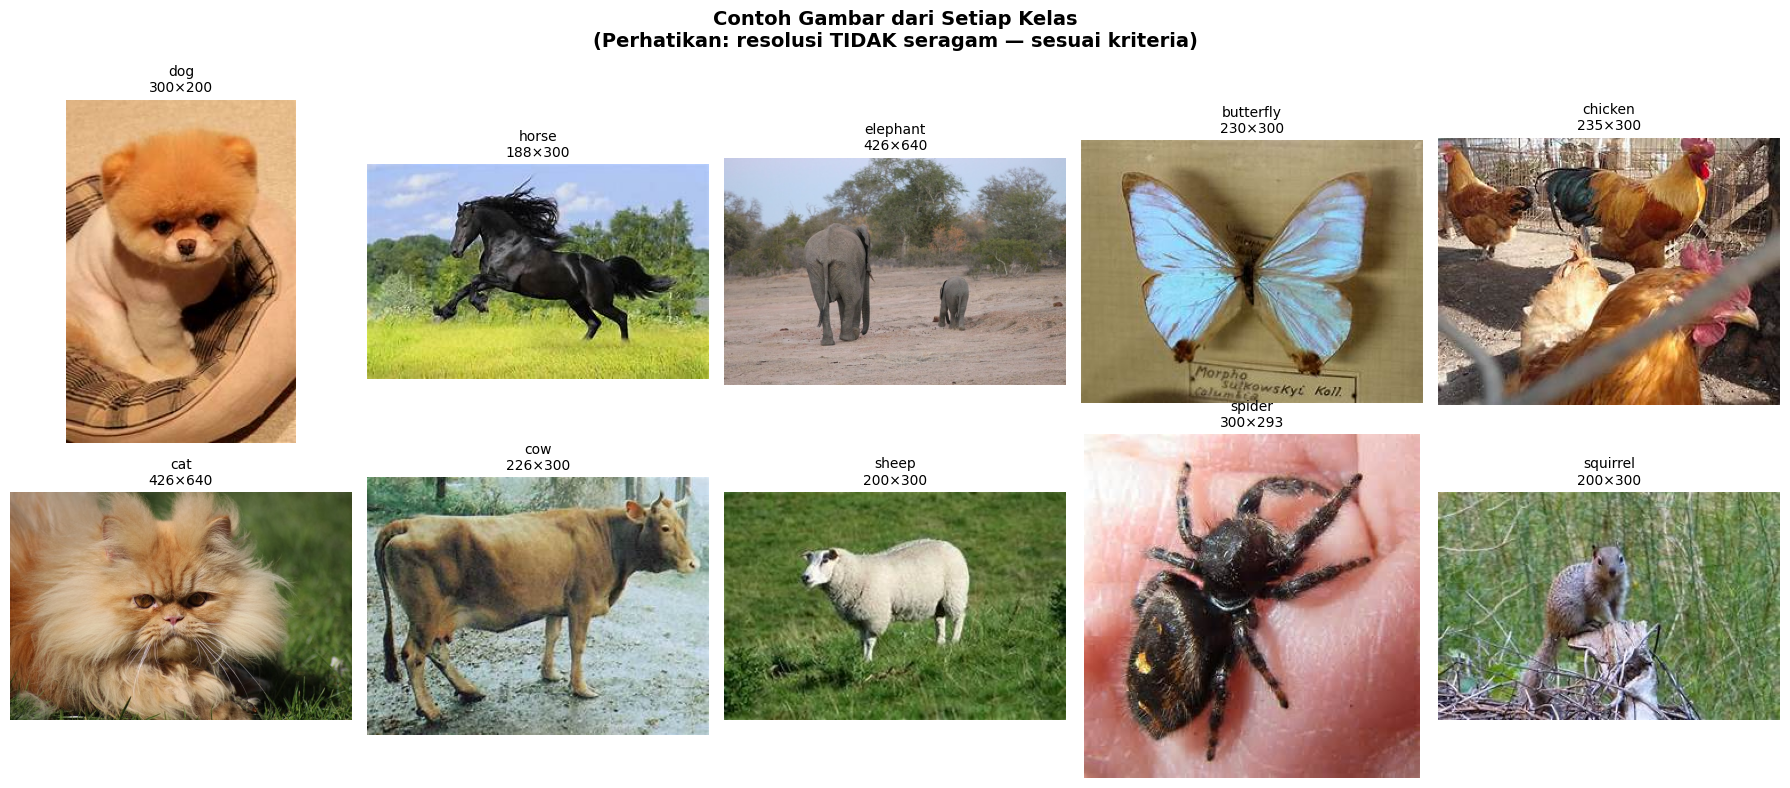

In [6]:
# Visualisasi contoh gambar dari setiap kelas (resolusi tidak seragam)
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
fig.suptitle(
    'Contoh Gambar dari Setiap Kelas\n'
    '(Perhatikan: resolusi TIDAK seragam — sesuai kriteria)',
    fontsize=14, fontweight='bold'
)

for idx, (folder_it, folder_en) in enumerate(TRANSLATE.items()):
    folder_path = os.path.join(RAW_DATA_DIR, folder_it)
    imgs = [f for f in os.listdir(folder_path) if f.lower().endswith(VALID_EXT)]
    img_path = os.path.join(folder_path, random.choice(imgs))
    img = mpimg.imread(img_path)
    ax = axes[idx // 5][idx % 5]
    ax.imshow(img)
    ax.set_title(f'{folder_en}\n{img.shape[0]}×{img.shape[1]}', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/sample_images.png', dpi=150, bbox_inches='tight')
plt.show()


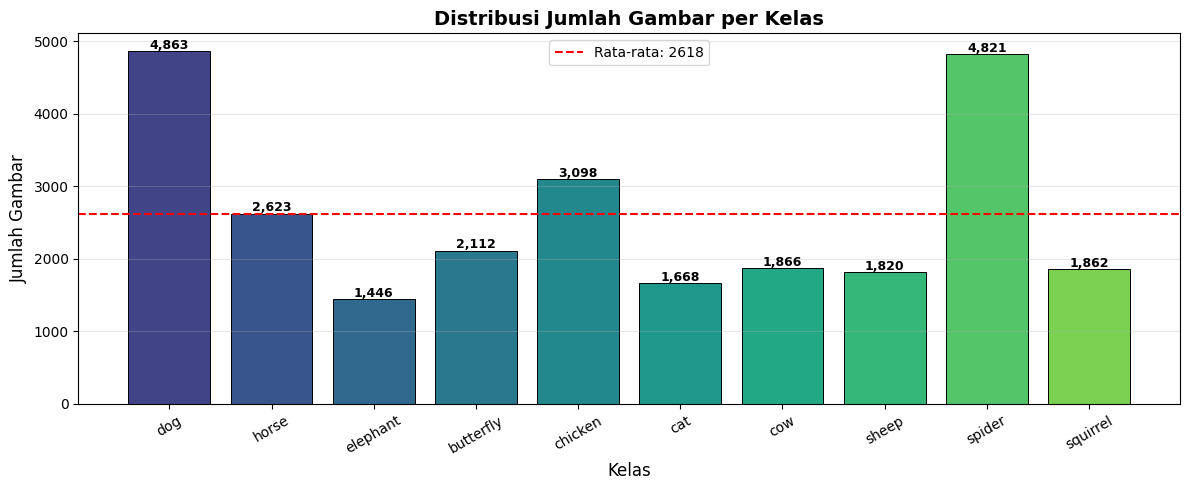

In [7]:

fig, ax = plt.subplots(figsize=(12, 5))
classes = list(class_counts.keys())
counts  = list(class_counts.values())
colors  = plt.cm.viridis(np.linspace(0.2, 0.8, len(classes)))

bars = ax.bar(classes, counts, color=colors, edgecolor='black', linewidth=0.7)
ax.axhline(np.mean(counts), color='red', linestyle='--', linewidth=1.5,
           label=f'Rata-rata: {np.mean(counts):.0f}')

for bar, c in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
            f'{c:,}', ha='center', fontweight='bold', fontsize=9)

ax.set_title('Distribusi Jumlah Gambar per Kelas', fontsize=14, fontweight='bold')
ax.set_xlabel('Kelas', fontsize=12)
ax.set_ylabel('Jumlah Gambar', fontsize=12)
ax.tick_params(axis='x', rotation=30)
ax.legend()
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('/content/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


## 3. Data Preprocessing
### 3.1 Stratified Train / Validation / Test Split


In [8]:
# Split Dataset:  70% Train | 15% Val | 15% Test

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df['label'],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['label'],
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

total = len(df)
print('=' * 45)
print(f'  Train : {len(train_df):>6,} gambar ({len(train_df)/total*100:.1f}%)')
print(f'  Val   : {len(val_df):>6,} gambar ({len(val_df)/total*100:.1f}%)')
print(f'  Test  : {len(test_df):>6,} gambar ({len(test_df)/total*100:.1f}%)')
print(f'  Total : {total:>6,} gambar')
print('=' * 45)

assert set(train_df.filepath).isdisjoint(val_df.filepath)
assert set(train_df.filepath).isdisjoint(test_df.filepath)
assert set(val_df.filepath).isdisjoint(test_df.filepath)


  Train : 18,325 gambar (70.0%)
  Val   :  3,927 gambar (15.0%)
  Test  :  3,927 gambar (15.0%)
  Total : 26,179 gambar


### 3.2 Image Data Generator & Augmentasi


In [9]:
# ================================================================
# KONFIGURASI GENERATOR
# ================================================================
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale            = 1./255,
    rotation_range     = 20,
    width_shift_range  = 0.15,
    height_shift_range = 0.15,
    shear_range        = 0.15,
    zoom_range         = 0.15,
    brightness_range   = [0.8, 1.2],
    horizontal_flip    = True,
    fill_mode          = 'nearest'
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col       = 'filepath',
    y_col       = 'label',
    target_size = IMG_SIZE,
    batch_size  = BATCH_SIZE,
    class_mode  = 'categorical',
    shuffle     = True,
    seed        = SEED
)

val_generator = val_test_datagen.flow_from_dataframe(
    val_df,
    x_col       = 'filepath',
    y_col       = 'label',
    target_size = IMG_SIZE,
    batch_size  = BATCH_SIZE,
    class_mode  = 'categorical',
    shuffle     = False
)

test_generator = val_test_datagen.flow_from_dataframe(
    test_df,
    x_col       = 'filepath',
    y_col       = 'label',
    target_size = IMG_SIZE,
    batch_size  = BATCH_SIZE,
    class_mode  = 'categorical',
    shuffle     = False
)

NUM_CLASSES = len(train_generator.class_indices)
CLASS_NAMES = list(train_generator.class_indices.keys())
print(f'Jumlah kelas : {NUM_CLASSES}')
print(f'Nama kelas   : {CLASS_NAMES}')
print(f'Input shape  : {IMG_SIZE + (3,)}')

train_eval_generator = val_test_datagen.flow_from_dataframe(
    train_df, x_col='filepath', y_col='label', target_size=IMG_SIZE,
    batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False,
    classes=CLASS_NAMES
)
assert train_generator.class_indices == val_generator.class_indices == test_generator.class_indices == train_eval_generator.class_indices
assert train_generator.samples == len(train_df)
assert val_generator.samples == len(val_df)
assert test_generator.samples == len(test_df)


Found 18325 validated image filenames belonging to 10 classes.
Found 3927 validated image filenames belonging to 10 classes.
Found 3927 validated image filenames belonging to 10 classes.
Jumlah kelas : 10
Nama kelas   : ['butterfly', 'cat', 'chicken', 'cow', 'dog', 'elephant', 'horse', 'sheep', 'spider', 'squirrel']
Input shape  : (224, 224, 3)
Found 18325 validated image filenames belonging to 10 classes.


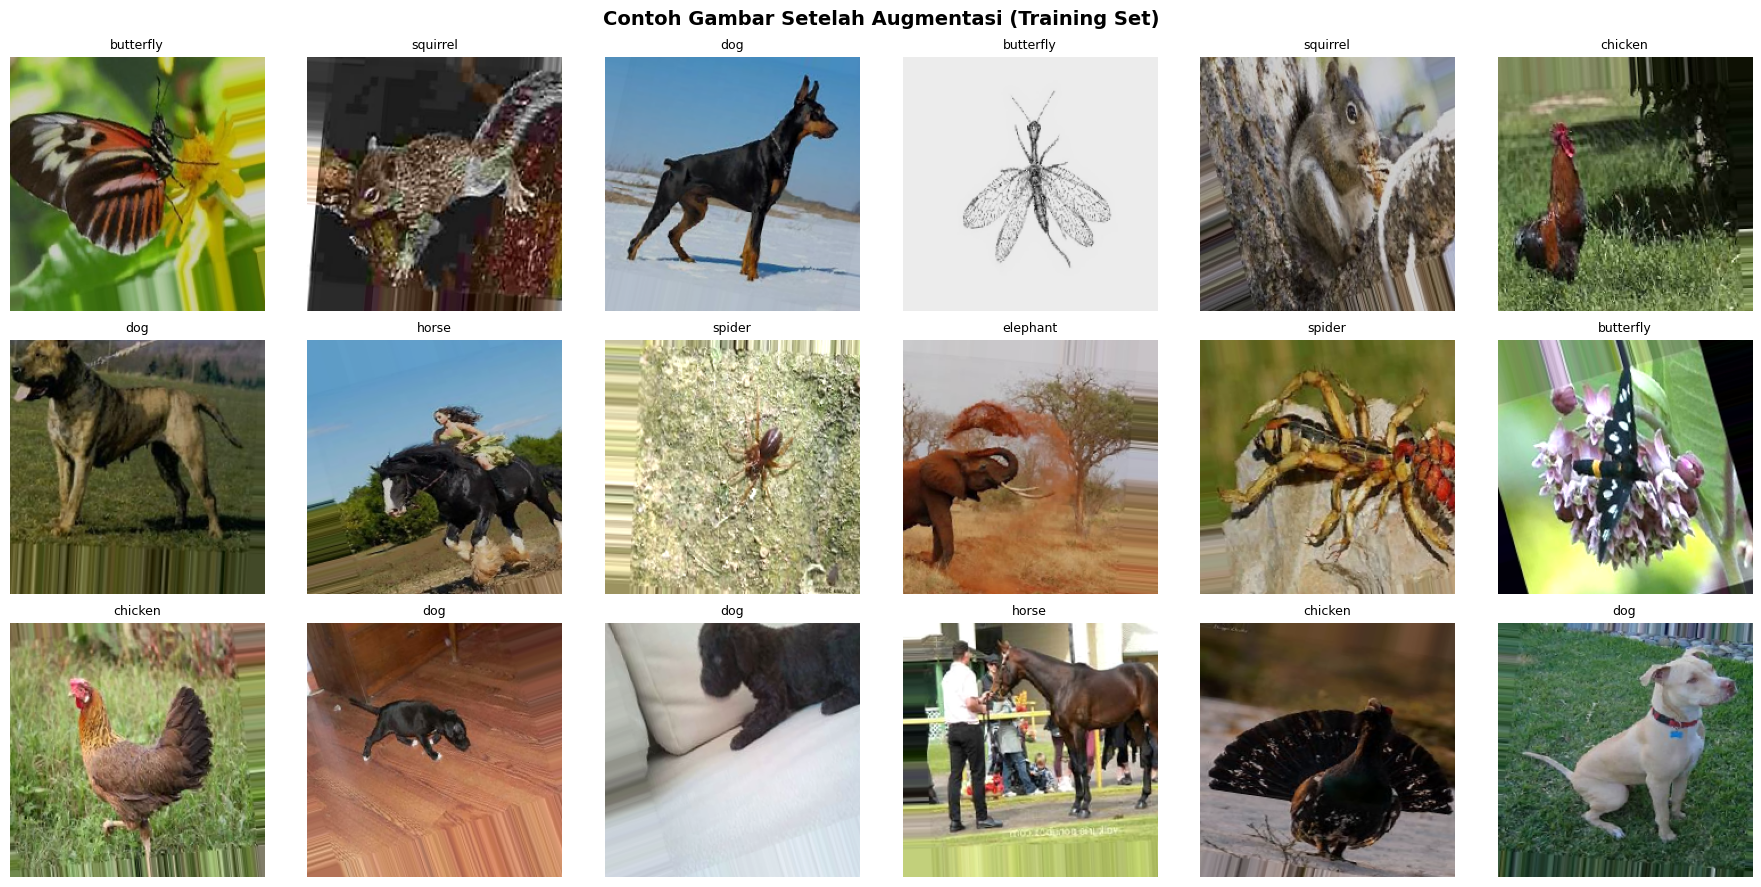

In [10]:
batch_imgs, batch_labels = next(train_generator)

fig, axes = plt.subplots(3, 6, figsize=(18, 9))
fig.suptitle('Contoh Gambar Setelah Augmentasi (Training Set)',
             fontsize=14, fontweight='bold')

for i, ax in enumerate(axes.flat):
    if i < len(batch_imgs):
        ax.imshow(batch_imgs[i])
        ax.set_title(CLASS_NAMES[np.argmax(batch_labels[i])], fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/augmented_samples.png', dpi=150, bbox_inches='tight')
plt.show()


In [11]:
classes      = np.unique(train_generator.classes)
class_weights = compute_class_weight(
    class_weight = 'balanced',
    classes      = classes,
    y            = train_generator.classes
)
class_weights_dict = dict(enumerate(class_weights))

print('Class weights:')
for idx, (name, w) in enumerate(zip(CLASS_NAMES, class_weights)):
    print(f'  [{idx}] {name:<12} : {w:.4f}')


Class weights:
  [0] butterfly    : 1.2399
  [1] cat          : 1.5689
  [2] chicken      : 0.8449
  [3] cow          : 1.4031
  [4] dog          : 0.5383
  [5] elephant     : 1.8108
  [6] horse        : 0.9981
  [7] sheep        : 1.4384
  [8] spider       : 0.5430
  [9] squirrel     : 1.4064


### 4.1 Arsitektur Model — MobileNetV2 + CNN Head


In [12]:
def build_cnn_model(input_shape, num_classes):
    """MobileNetV2 backbone + custom CNN head dalam Sequential."""

    base_model = MobileNetV2(
        weights      = 'imagenet',
        include_top  = False,
        input_shape  = input_shape
    )

    base_model.trainable = True
    for layer in base_model.layers[:-20]:
        layer.trainable = False

    model = Sequential([

        base_model,

        Conv2D(64, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        GlobalAveragePooling2D(),
        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ], name='Animals10_MobileNetV2')

    return model


keras.backend.clear_session()
INPUT_SHAPE = IMG_SIZE + (3,)
model = build_cnn_model(INPUT_SHAPE, NUM_CLASSES)

model.compile(
    optimizer = Adam(learning_rate=1e-4),  # LR kecil untuk fine-tuning
    loss      = 'categorical_crossentropy',
    metrics   = ['accuracy']
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "Animals10_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 7, 7, 64)       │       737,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 7, 7, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 3, 3, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,106,570 (11.85 MB)

 Trainable params: 2,053,770 (7.83 MB)

 Non-trainable params: 1,052,800 (4.02 MB)

### 4.2 Callbacks


In [13]:
# DEFINISI CALLBACKS
early_stopping = EarlyStopping(
    monitor              = 'val_accuracy',
    patience             = 10,
    restore_best_weights = True,
    verbose              = 1,
    mode                 = 'max'
)

reduce_lr = ReduceLROnPlateau(
    monitor  = 'val_loss',
    factor   = 0.3,
    patience = 4,
    min_lr   = 1e-7,
    verbose  = 1
)

RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
RUN_DIR = Path('/content/checkpoints') / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
CHECKPOINT_PATH = RUN_DIR / 'best_model.keras'
TRAINING_COMPLETED = EVALUATION_COMPLETED = EXPORT_COMPLETED = False
history = None
best_model = None
checkpoint = ModelCheckpoint(
    filepath          = str(CHECKPOINT_PATH),
    monitor           = 'val_accuracy',
    save_best_only    = True,
    save_weights_only = False,
    verbose           = 1,
    mode              = 'max'
)

class AccuracyThresholdCallback(tf.keras.callbacks.Callback):
    """Hentikan training otomatis saat target akurasi tercapai."""
    def __init__(self, threshold=0.95):
        super().__init__()
        self.threshold = threshold

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        train_acc = logs.get('accuracy', 0)
        val_acc   = logs.get('val_accuracy', 0)
        if train_acc >= self.threshold and val_acc >= self.threshold:
            print(f'\n✅ Target {self.threshold*100:.0f}% tercapai! '
                  f'Train: {train_acc*100:.2f}% | Val: {val_acc*100:.2f}%'
                  f' → Training dihentikan.')
            self.model.stop_training = True

accuracy_callback = AccuracyThresholdCallback(threshold=0.95)

csv_logger = keras.callbacks.CSVLogger(str(RUN_DIR / 'training_log.csv'), append=False)
CALLBACKS = [early_stopping, reduce_lr, checkpoint, accuracy_callback, csv_logger]

print('Callbacks yang digunakan:')
for cb in CALLBACKS:
    print(f'  ✔ {cb.__class__.__name__}')

TRAINING_STARTED = False
print(f'Run ID: {RUN_ID}')


Callbacks yang digunakan:
  ✔ EarlyStopping
  ✔ ReduceLROnPlateau
  ✔ ModelCheckpoint
  ✔ AccuracyThresholdCallback
  ✔ CSVLogger
Run ID: 20261015T130914Z_2dcf3d3c


### 4.3 Training Model


In [14]:
# Arsitektur, class weights, batas epoch, dan target callback dipertahankan.
EPOCHS = 50
TRAINING_COMPLETED = EVALUATION_COMPLETED = EXPORT_COMPLETED = False
history = None
best_model = None

if TRAINING_STARTED:
    raise RuntimeError('Untuk pelatihan ulang, jalankan kembali sel arsitektur dan callbacks terlebih dahulu.')
TRAINING_STARTED = True
print(f'RUN_TRAINING: {RUN_ID}')
train_generator.reset()
val_generator.reset()

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    class_weight=class_weights_dict,
    callbacks=CALLBACKS,
    verbose=2
)
if not history.epoch or not CHECKPOINT_PATH.is_file():
    raise RuntimeError('Pelatihan tidak menghasilkan history/checkpoint yang valid.')
for metric in ('accuracy', 'val_accuracy', 'loss', 'val_loss'):
    values = history.history[metric]
    assert len(values) == len(history.epoch) and np.isfinite(values).all(), metric
history_data = {k: [float(v) for v in values] for k, values in history.history.items()}
(RUN_DIR / 'history.json').write_text(json.dumps(history_data, indent=2))
TRAINING_COMPLETED = True
print(f'TRAINING_COMPLETED: {RUN_ID} | {len(history.epoch)} epoch selesai')
print('Berakhir normal: batas epoch atau callback; bukan interupsi manual.')


RUN_TRAINING: 20261015T130914Z_2dcf3d3c
Epoch 1/50

Epoch 1: val_accuracy improved from None to 0.93099, saving model to /content/checkpoints/20261015T130914Z_2dcf3d3c/best_model.keras

Epoch 1: finished saving model to /content/checkpoints/20261015T130914Z_2dcf3d3c/best_model.keras
573/573 - 340s - 594ms/step - accuracy: 0.7530 - loss: 0.8113 - val_accuracy: 0.9310 - val_loss: 0.2347 - learning_rate: 1.0000e-04
Epoch 2/50

Epoch 2: val_accuracy improved from 0.93099 to 0.95034, saving model to /content/checkpoints/20261015T130914Z_2dcf3d3c/best_model.keras

Epoch 2: finished saving model to /content/checkpoints/20261015T130914Z_2dcf3d3c/best_model.keras
573/573 - 298s - 519ms/step - accuracy: 0.8863 - loss: 0.3890 - val_accuracy: 0.9503 - val_loss: 0.1666 - learning_rate: 1.0000e-04
Epoch 3/50

Epoch 3: val_accuracy improved from 0.95034 to 0.95671, saving model to /content/checkpoints/20261015T130914Z_2dcf3d3c/best_model.keras

Epoch 3: finished saving model to /content/checkpoints/2

## 5. Evaluasi & Visualisasi
### 5.1 Plot Akurasi & Loss


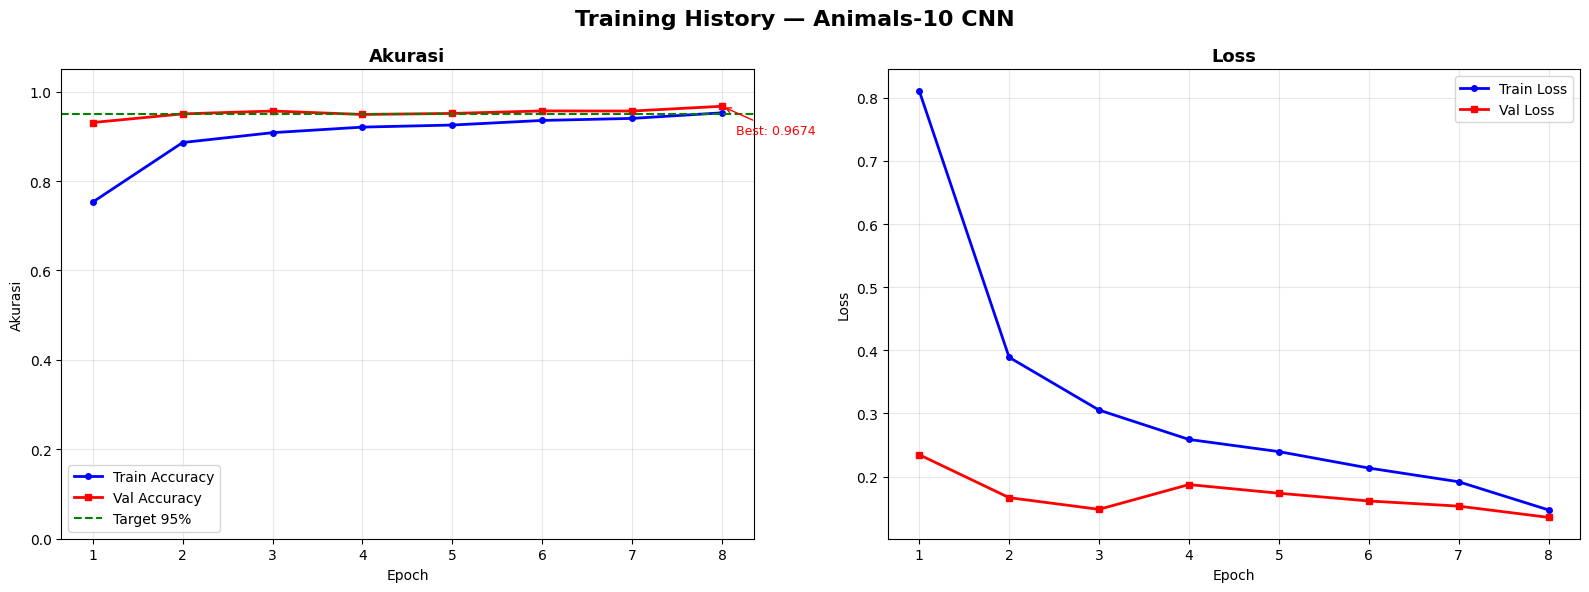

Best Train Accuracy : 0.9527 (95.27%)
Best Val Accuracy   : 0.9674 (96.74%)
Nilai maksimum di atas adalah riwayat epoch; evaluasi checkpoint ada pada sel berikutnya.


In [15]:
assert TRAINING_COMPLETED and history is not None, 'Jalankan pelatihan hingga selesai.'
# ================================================================
# PLOT HISTORY — Accuracy & Loss
# ================================================================
acc      = history.history['accuracy']
val_acc  = history.history['val_accuracy']
loss     = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Training History — Animals-10 CNN', fontsize=16, fontweight='bold')

# ── Akurasi ──
axes[0].plot(epochs_range, acc,     'b-o', lw=2, ms=4, label='Train Accuracy')
axes[0].plot(epochs_range, val_acc, 'r-s', lw=2, ms=4, label='Val Accuracy')
axes[0].axhline(y=0.95, color='green', linestyle='--', lw=1.5, label='Target 95%')
axes[0].set_title('Akurasi', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Akurasi')
axes[0].set_ylim([0, 1.05])
axes[0].legend()
axes[0].grid(True, alpha=0.3)

best_val_epoch = val_acc.index(max(val_acc)) + 1
axes[0].annotate(
    f'Best: {max(val_acc):.4f}',
    xy=(best_val_epoch, max(val_acc)),
    xytext=(10, -20), textcoords='offset points',
    fontsize=9, color='red',
    arrowprops=dict(arrowstyle='->', color='red')
)

# ── Loss ──
axes[1].plot(epochs_range, loss,     'b-o', lw=2, ms=4, label='Train Loss')
axes[1].plot(epochs_range, val_loss, 'r-s', lw=2, ms=4, label='Val Loss')
axes[1].set_title('Loss', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/content/training_history.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Best Train Accuracy : {max(acc):.4f} ({max(acc)*100:.2f}%)')
print(f'Best Val Accuracy   : {max(val_acc):.4f} ({max(val_acc)*100:.2f}%)')

print('Nilai maksimum di atas adalah riwayat epoch; evaluasi checkpoint ada pada sel berikutnya.')


### 5.2 Evaluasi pada Test Set


In [16]:
# Evaluasi seluruh split dengan satu checkpoint terbaik menurut validation accuracy.
assert TRAINING_COMPLETED and history is not None, 'Pelatihan belum selesai.'
EVALUATION_COMPLETED = EXPORT_COMPLETED = False
best_model = keras.models.load_model(str(CHECKPOINT_PATH))
CHECKPOINT_SHA256 = hashlib.sha256(CHECKPOINT_PATH.read_bytes()).hexdigest()
train_eval_generator.reset()
val_generator.reset()
test_generator.reset()
train_loss, train_acc = best_model.evaluate(train_eval_generator, verbose=2)
val_loss_final, val_acc_final = best_model.evaluate(val_generator, verbose=2)
test_loss, test_acc = best_model.evaluate(test_generator, verbose=2)
results = {
    'run_id': RUN_ID, 'completed_epochs': len(history.epoch),
    'best_epoch': int(np.argmax(history.history['val_accuracy']) + 1),
    'checkpoint_sha256': CHECKPOINT_SHA256,
    'train_accuracy': float(train_acc), 'train_loss': float(train_loss),
    'validation_accuracy': float(val_acc_final), 'validation_loss': float(val_loss_final),
    'test_accuracy': float(test_acc), 'test_loss': float(test_loss),
    'train_samples': train_eval_generator.samples, 'validation_samples': val_generator.samples,
    'test_samples': test_generator.samples,
    'minimum_accuracy': 0.85,
    'class_names': CLASS_NAMES, 'input_scaling': 'RGB float32 / 255.0'
}
print(f'Run ID: {RUN_ID}')
print(f'Train Accuracy      : {train_acc:.4f} ({train_acc * 100:.2f}%)')
print(f'Validation Accuracy : {val_acc_final:.4f} ({val_acc_final * 100:.2f}%)')
print(f'Test Accuracy       : {test_acc:.4f} ({test_acc * 100:.2f}%)')
(RUN_DIR / 'evaluation.json').write_text(json.dumps(results, indent=2))
# Test hanya untuk evaluasi akhir, tidak dipakai callback/pemilihan checkpoint.
if not (np.isfinite(train_acc) and np.isfinite(test_acc) and train_acc >= 0.85 and test_acc >= 0.85):
    raise RuntimeError('Training dan testing belum sama-sama mencapai 85%; ekspor submission diblokir.')
EVALUATION_COMPLETED = True
print(f'EVALUATION_COMPLETED: {RUN_ID} | training dan testing memenuhi minimum 85%.')


573/573 - 58s - 101ms/step - accuracy: 0.9849 - loss: 0.0483
123/123 - 13s - 106ms/step - accuracy: 0.9674 - loss: 0.1354
123/123 - 9s - 77ms/step - accuracy: 0.9628 - loss: 0.1357
Run ID: 20261015T130914Z_2dcf3d3c
Train Accuracy      : 0.9849 (98.49%)
Validation Accuracy : 0.9674 (96.74%)
Test Accuracy       : 0.9628 (96.28%)
EVALUATION_COMPLETED: 20261015T130914Z_2dcf3d3c | training dan testing memenuhi minimum 85%.


### 5.3 Confusion Matrix & Classification Report


123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 111ms/step
Classification Report:
              precision    recall  f1-score   support

   butterfly       0.97      0.98      0.98       317
         cat       0.96      0.95      0.96       250
     chicken       0.98      0.97      0.98       465
         cow       0.95      0.93      0.94       280
         dog       0.97      0.94      0.95       729
    elephant       0.93      0.99      0.96       217
       horse       0.93      0.97      0.95       394
       sheep       0.91      0.95      0.93       273
      spider       0.99      0.98      0.99       723
    squirrel       0.97      0.96      0.97       279

    accuracy                           0.96      3927
   macro avg       0.96      0.96      0.96      3927
weighted avg       0.96      0.96      0.96      3927



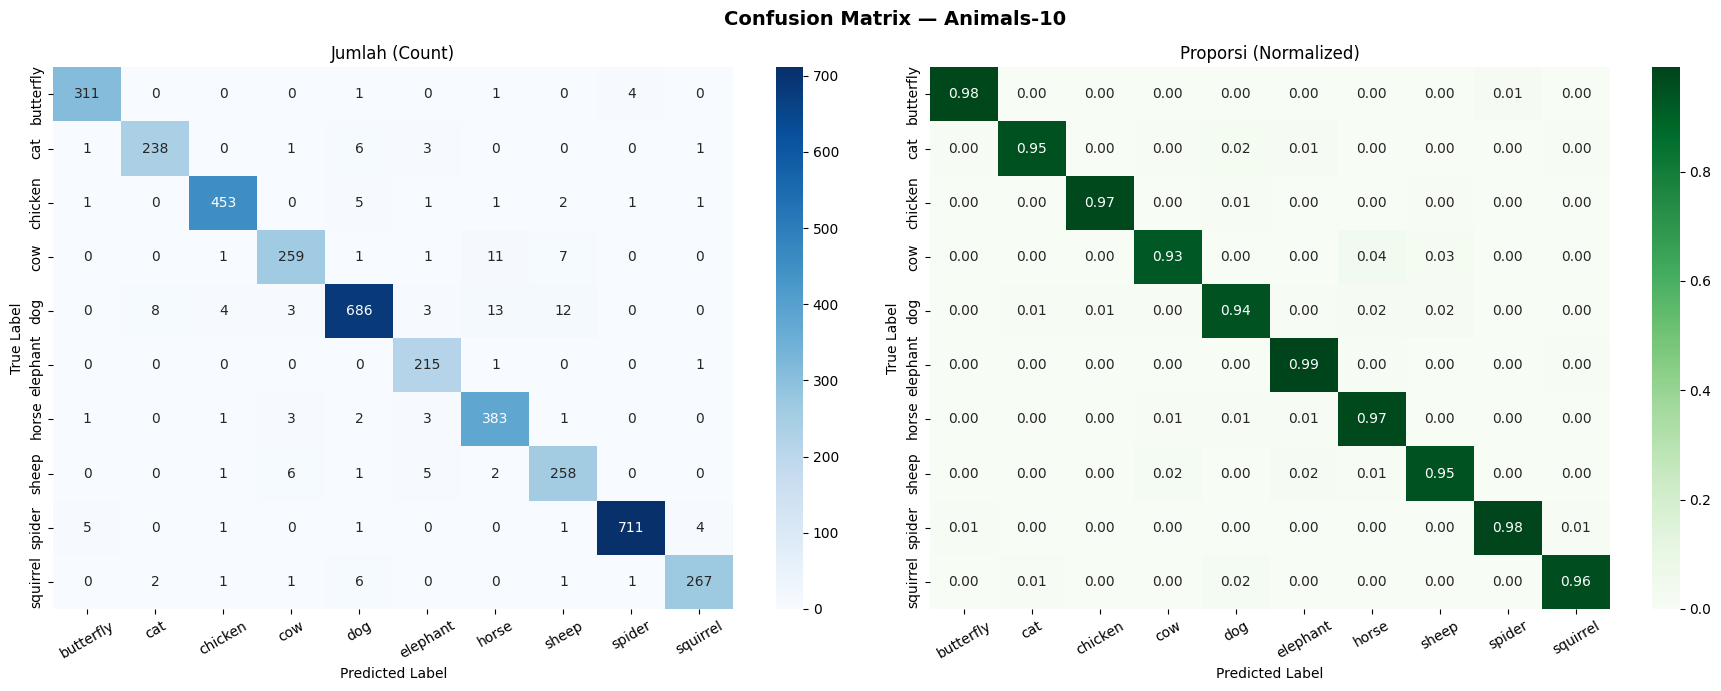

In [17]:
# ================================================================
# CONFUSION MATRIX & CLASSIFICATION REPORT
# ================================================================
test_generator.reset()
y_pred_probs = best_model.predict(test_generator, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)[:len(test_generator.classes)]
y_true = test_generator.classes

print('Classification Report:')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

# ── Plot Confusion Matrix ──
cm            = confusion_matrix(y_true, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Confusion Matrix — Animals-10', fontsize=14, fontweight='bold')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title('Jumlah (Count)')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')
axes[0].tick_params(axis='x', rotation=30)

sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title('Proporsi (Normalized)')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('/content/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Konversi & Penyimpanan Model


In [18]:
# Ketiga format dibuat dari checkpoint sesi ini yang sudah dievaluasi.
assert TRAINING_COMPLETED and EVALUATION_COMPLETED, 'Pelatihan/evaluasi belum valid.'
assert hashlib.sha256(CHECKPOINT_PATH.read_bytes()).hexdigest() == CHECKPOINT_SHA256
EXPORT_COMPLETED = False
MODEL_EXPORT_RUN_ID = None
EXPORT_ROOT = Path('/content/exports') / RUN_ID
SAVED_MODEL_DIR = str(EXPORT_ROOT / 'saved_model')
TFJS_DIR = str(EXPORT_ROOT / 'tfjs_model')
TFLITE_PATH = str(EXPORT_ROOT / 'tflite' / 'model.tflite')
# Sel konversi dapat diulang; kosongkan hanya direktori ekspor Run ID ini.
if EXPORT_ROOT.exists():
    shutil.rmtree(EXPORT_ROOT)
EXPORT_ROOT.mkdir(parents=True)
best_model.export(SAVED_MODEL_DIR)
reloaded_saved = tf.saved_model.load(SAVED_MODEL_DIR)
# Uji hasil ekspor terhadap model sumber pada satu batch test.
probe_images, _ = test_generator[0]
probe_images = probe_images[:4].astype(np.float32)
keras_probs = best_model(probe_images, training=False).numpy()
saved_probs = reloaded_saved.serve(tf.constant(probe_images)).numpy()
np.testing.assert_allclose(keras_probs, saved_probs, rtol=1e-4, atol=1e-5)
SAVED_EXPORT_RUN_ID = RUN_ID
print('SavedModel disimpan dan prediksi cocok dengan checkpoint sumber.')


Saved artifact at '/content/exports/20261015T130914Z_2dcf3d3c/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  137781476270032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137778233309712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137778233310288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137781476266576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137779201833104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137778233307984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137778233298960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137778233297616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137778233299152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137778233308176: TensorSpec(shape=(), dtype=

In [19]:
assert EVALUATION_COMPLETED and SAVED_EXPORT_RUN_ID == RUN_ID
converter = tf.lite.TFLiteConverter.from_saved_model(SAVED_MODEL_DIR)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
Path(TFLITE_PATH).parent.mkdir(parents=True, exist_ok=True)
Path(TFLITE_PATH).write_bytes(tflite_model)
Path(TFLITE_PATH).with_name('label.txt').write_text('\n'.join(CLASS_NAMES) + '\n')
probe_interpreter = tf.lite.Interpreter(model_path=TFLITE_PATH)
probe_interpreter.allocate_tensors()
probe_input = probe_interpreter.get_input_details()[0]
probe_output = probe_interpreter.get_output_details()[0]
assert tuple(probe_input['shape']) == (1, *IMG_SIZE, 3)
assert probe_input['dtype'] == np.float32
assert probe_output['shape'][-1] == NUM_CLASSES
probe_interpreter.set_tensor(probe_input['index'], probe_images[:1])
probe_interpreter.invoke()
tflite_probs = probe_interpreter.get_tensor(probe_output['index'])
assert np.isfinite(tflite_probs).all()
print(f'TF-Lite: {Path(TFLITE_PATH).stat().st_size / 1024**2:.2f} MB')
print(f'Deviasi probabilitas pada satu sampel setelah quantization: {np.max(np.abs(tflite_probs - keras_probs[:1])):.6f}')
TFLITE_EXPORT_RUN_ID = RUN_ID


TF-Lite: 3.23 MB
Deviasi probabilitas pada satu sampel setelah quantization: 0.058107


In [21]:
from pathlib import Path
import subprocess
import sys

# Pasang uv di folder tersendiri.
# Paket TensorFlow pada runtime training tidak diganti.
UV_DIR = Path("/content/uv_converter_tools")
UV_BIN = UV_DIR / "bin" / "uv"

if not UV_BIN.is_file():
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install",
            "--no-user", "--target", str(UV_DIR), "uv"
        ],
        check=True
    )

# Gunakan Python 3.11 khusus untuk converter.
subprocess.run(
    [str(UV_BIN), "python", "install", "3.11"],
    check=True
)

# Folder baru agar tidak memakai environment yang tadi gagal dibuat.
CONVERTER_ENV = Path("/content/tfjs_converter_env_py311")
CONVERTER_PYTHON = CONVERTER_ENV / "bin" / "python"
CONVERTER_BIN = CONVERTER_ENV / "bin" / "tensorflowjs_converter"

if not CONVERTER_PYTHON.is_file():
    subprocess.run(
        [
            str(UV_BIN), "venv",
            "--python", "3.11",
            str(CONVERTER_ENV)
        ],
        check=True
    )

# Instal dependensi hanya ke environment converter.
subprocess.run(
    [
        str(UV_BIN), "pip", "install",
        "--python", str(CONVERTER_PYTHON),
        "tensorflow==2.19.0",
        "tensorflowjs==4.22.0",
        "tensorflow-decision-forests==1.12.0",
        "jax==0.4.38",
        "jaxlib==0.4.38"
    ],
    check=True
)

assert CONVERTER_BIN.is_file(), "Converter belum terpasang."

subprocess.run(
    [str(CONVERTER_PYTHON), "--version"],
    check=True
)

print("Environment converter siap.")

Environment converter siap. Lanjutkan ke sel berikutnya.


In [38]:
import subprocess

# Pasang hanya ke environment converter.
subprocess.run(
    [
        str(UV_BIN), "pip", "install",
        "--python", str(CONVERTER_PYTHON),
        "setuptools==80.9.0"
    ],
    check=True
)

# Verifikasi impor converter dalam proses terpisah.
verification = subprocess.run(
    [
        str(CONVERTER_PYTHON), "-c",
        "import pkg_resources; "
        "import tensorflowjs; "
        "print('Converter berhasil diimpor.')"
    ],
    capture_output=True,
    text=True
)

if verification.returncode != 0:
    raise RuntimeError(
        "Verifikasi converter gagal:\n"
        + (verification.stderr or verification.stdout)[-8000:]
    ) from None

print(verification.stdout)

Converter berhasil diimpor.



In [39]:
from pathlib import Path
import subprocess

UV_BIN = Path("/content/uv_converter_tools/bin/uv")
CONVERTER_ENV = Path("/content/tfjs_converter_env_py311")
CONVERTER_PYTHON = CONVERTER_ENV / "bin" / "python"
CONVERTER_BIN = CONVERTER_ENV / "bin" / "tensorflowjs_converter"

# Perbaiki hanya environment converter.
subprocess.run(
    [
        str(UV_BIN), "pip", "install",
        "--python", str(CONVERTER_PYTHON),
        "--reinstall-package", "ydf",
        "tensorflow==2.19.0",
        "tensorflow-decision-forests==1.12.0",
        "tensorflowjs==4.22.0",
        "ydf==0.11.0",
        "protobuf==5.29.6"
    ],
    check=True
)

# Pastikan converter benar-benar dapat diimpor.
verification = subprocess.run(
    [
        str(CONVERTER_PYTHON), "-c",
        "import tensorflowjs; "
        "from importlib.metadata import version; "
        "print('TensorFlowJS:', version('tensorflowjs')); "
        "print('YDF:', version('ydf')); "
        "print('Protobuf:', version('protobuf'))"
    ],
    capture_output=True,
    text=True
)

if verification.returncode != 0:
    raise RuntimeError(
        "Verifikasi converter gagal:\n"
        + (verification.stderr or verification.stdout)[-8000:]
    ) from None

print(verification.stdout)
print("Dependensi converter berhasil diverifikasi.")

TensorFlowJS: 4.22.0
YDF: 0.11.0
Protobuf: 5.29.6

Dependensi converter berhasil diverifikasi.


In [44]:
from pathlib import Path
import subprocess
import hashlib
import shutil
import json
import os

assert TRAINING_COMPLETED and EVALUATION_COMPLETED
assert SAVED_EXPORT_RUN_ID == TFLITE_EXPORT_RUN_ID == RUN_ID
assert (
    hashlib.sha256(Path(CHECKPOINT_PATH).read_bytes()).hexdigest()
    == CHECKPOINT_SHA256
), "Checkpoint berbeda dari yang sudah dievaluasi."

EXPORT_COMPLETED = False
MODEL_EXPORT_RUN_ID = None

CONVERTER_BIN = Path(
    "/content/tfjs_converter_env_py311/bin/tensorflowjs_converter"
)

TFJS_DIR = str(Path(EXPORT_ROOT) / "tfjs_model")
staging_dir = Path(EXPORT_ROOT) / "tfjs_model_staging"

if staging_dir.exists():
    shutil.rmtree(staging_dir)

converter_env = os.environ.copy()
converter_env["CUDA_VISIBLE_DEVICES"] = "-1"
converter_env.pop("PYTHONPATH", None)
converter_env.pop("PYTHONHOME", None)

print("Mengonversi SavedModel ke TFJS...")

conversion = subprocess.run(
    [
        str(CONVERTER_BIN),
        "--input_format=tf_saved_model",
        "--output_format=tfjs_graph_model",
        "--signature_name=serving_default",
        "--saved_model_tags=serve",
        str(SAVED_MODEL_DIR),
        str(staging_dir)
    ],
    env=converter_env,
    capture_output=True,
    text=True
)

if conversion.returncode != 0:
    raise RuntimeError(
        "Konversi TFJS gagal:\n"
        + (conversion.stderr or conversion.stdout)[-10000:]
    ) from None

manifest = json.loads(
    (staging_dir / "model.json").read_text()
)

assert manifest.get("format") == "graph-model"
assert manifest.get("modelTopology"), "Graph TFJS kosong."
assert manifest.get("weightsManifest"), "Manifest bobot kosong."

for group in manifest["weightsManifest"]:
    assert group.get("paths"), "Daftar shard kosong."
    for shard in group["paths"]:
        path = staging_dir / shard
        assert path.is_file() and path.stat().st_size > 0, shard

if Path(TFJS_DIR).exists():
    shutil.rmtree(TFJS_DIR)

staging_dir.rename(Path(TFJS_DIR))

MODEL_EXPORT_RUN_ID = RUN_ID
EXPORT_COMPLETED = True

print(f"EXPORT_COMPLETED: {RUN_ID}")
print("Konversi TFJS selesai dan berkasnya lengkap.")

Mengonversi SavedModel ke TFJS...
EXPORT_COMPLETED: 20261015T130914Z_2dcf3d3c
Konversi TFJS selesai dan berkasnya lengkap.


## 7. Inference dengan TF-Lite


In [45]:
# ================================================================
# INFERENCE MENGGUNAKAN TF-LITE INTERPRETER
# ================================================================

def preprocess_image(img_path, img_size=IMG_SIZE):
    """Load & preprocess gambar untuk inferensi."""
    img       = Image.open(img_path).convert('RGB').resize(img_size)
    img_array = np.array(img, dtype=np.float32) / 255.0
    return np.expand_dims(img_array, axis=0)   # shape: (1, H, W, 3)


def predict_tflite(interpreter, img_path):
    """Jalankan inferensi TF-Lite dan kembalikan array probabilitas."""
    input_details  = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    interpreter.set_tensor(input_details[0]['index'], preprocess_image(img_path))
    interpreter.invoke()
    return interpreter.get_tensor(output_details[0]['index'])[0]


# Load interpreter
interpreter = tf.lite.Interpreter(model_path=TFLITE_PATH)
interpreter.allocate_tensors()
print('✅ TF-Lite Interpreter siap!')

# Ambil 1 gambar per kelas dari test set
sample_images = []
for class_name in CLASS_NAMES:
    class_imgs = test_df[test_df['label'] == class_name]['filepath'].tolist()
    if class_imgs:
        sample_images.append((random.choice(class_imgs), class_name))

print(f'Melakukan inferensi pada {len(sample_images)} gambar...')


✅ TF-Lite Interpreter siap!
Melakukan inferensi pada 10 gambar...


  #  True         Predicted    Confidence  Status
-------------------------------------------------------
  1. butterfly    butterfly        99.30%  ✅
  2. cat          cat              99.96%  ✅
  3. chicken      chicken          99.99%  ✅
  4. cow          cow              99.98%  ✅
  5. dog          dog              99.51%  ✅
  6. elephant     elephant        100.00%  ✅
  7. horse        horse            99.10%  ✅
  8. sheep        sheep           100.00%  ✅
  9. spider       spider           92.80%  ✅
 10. squirrel     squirrel        100.00%  ✅
-------------------------------------------------------
Akurasi Inferensi: 10/10 = 100.0%


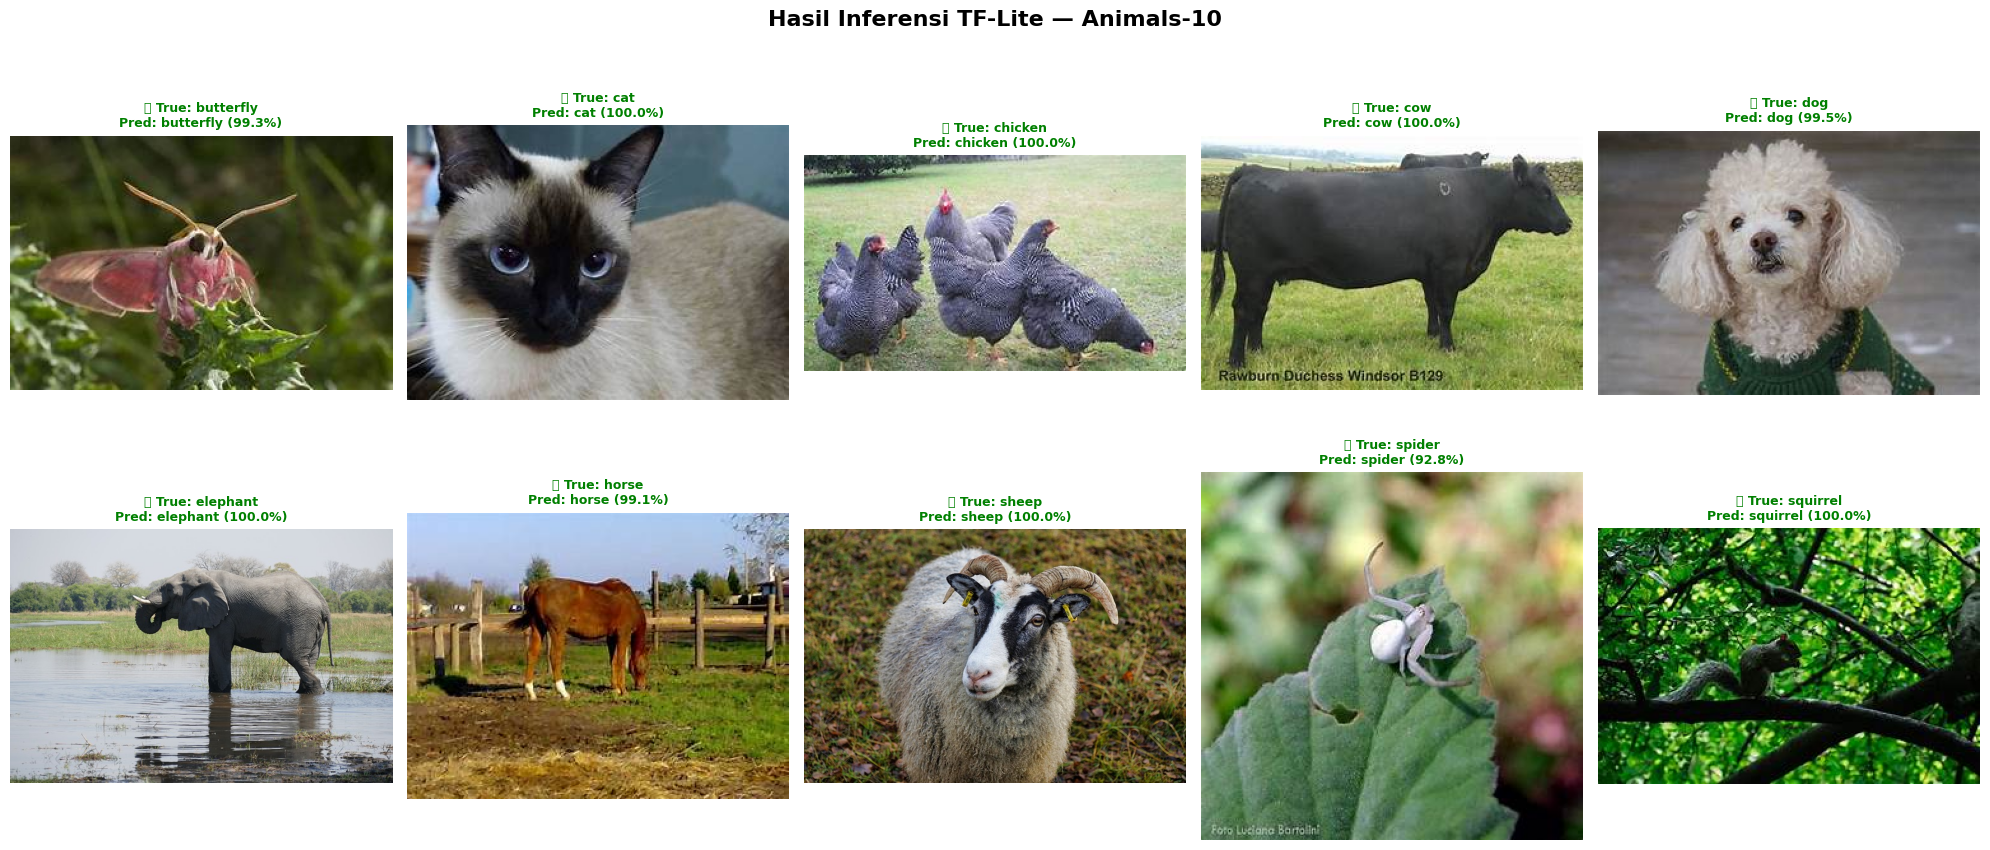


📄 Bukti inferensi tersimpan: /content/inference_results.png


In [46]:
# ── Tampilkan hasil inferensi ──
fig, axes = plt.subplots(2, 5, figsize=(20, 9))
fig.suptitle('Hasil Inferensi TF-Lite — Animals-10', fontsize=16, fontweight='bold')

correct = 0
print(f"{'#':>3}  {'True':<12} {'Predicted':<12} {'Confidence':>10}  Status")
print('-' * 55)

for idx, (img_path, true_label) in enumerate(sample_images):
    probs      = predict_tflite(interpreter, img_path)
    pred_idx   = np.argmax(probs)
    pred_label = CLASS_NAMES[pred_idx]
    confidence = probs[pred_idx] * 100
    is_correct = (pred_label == true_label)
    if is_correct:
        correct += 1

    ax = axes[idx // 5][idx % 5]
    ax.imshow(Image.open(img_path).convert('RGB'))
    color = 'green' if is_correct else 'red'
    icon  = '✅' if is_correct else '❌'
    ax.set_title(
        f'{icon} True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)',
        fontsize=9, color=color, fontweight='bold'
    )
    ax.axis('off')

    print(f"{idx+1:>3}. {true_label:<12} {pred_label:<12} {confidence:>9.2f}%  {icon}")

print('-' * 55)
print(f'Akurasi Inferensi: {correct}/{len(sample_images)} = {correct/len(sample_images)*100:.1f}%')

plt.tight_layout()
plt.savefig('/content/inference_results.png', dpi=150, bbox_inches='tight')
plt.show()
print('\n📄 Bukti inferensi tersimpan: /content/inference_results.png')


## 8. Simpan Notebook dengan Output & Buat ZIP Submission

In [ ]:
assert TRAINING_COMPLETED and EVALUATION_COMPLETED and EXPORT_COMPLETED
assert MODEL_EXPORT_RUN_ID == RUN_ID
print('Simpan lalu unduh notebook yang sedang dijalankan (dengan semua output).')
print('Unggah hanya file .ipynb hasil unduhan tersebut di bawah ini.')
notebook_upload = files.upload()
notebooks = [name for name in notebook_upload if name.endswith('.ipynb')]
assert len(notebooks) == 1, 'Unggah tepat satu notebook .ipynb.'
notebook_bytes = notebook_upload[notebooks[0]]
executed_nb = json.loads(notebook_bytes)
errors = [i for i, cell in enumerate(executed_nb['cells'])
          if any(o.get('output_type') == 'error' for o in cell.get('outputs', []))]
assert not errors, f'Notebook masih menyimpan output error pada sel {errors}.'
fit_cells = [cell for cell in executed_nb['cells'] if cell['cell_type'] == 'code'
             and re.search(r'^history\s*=\s*model\.fit\(', ''.join(cell.get('source', [])), re.MULTILINE)]
assert len(fit_cells) == 1
fit_output = ''.join(''.join(o.get('text', [])) for o in fit_cells[0].get('outputs', []))
assert fit_cells[0].get('execution_count') is not None
assert f'TRAINING_COMPLETED: {RUN_ID}' in fit_output, 'Output fit bukan pelatihan lengkap sesi ini.'
all_output = ''.join(''.join(o.get('text', [])) for cell in executed_nb['cells'] for o in cell.get('outputs', []))
assert f'EVALUATION_COMPLETED: {RUN_ID}' in all_output
assert f'EXPORT_COMPLETED: {RUN_ID}' in all_output
for relative in ('saved_model/saved_model.pb', 'saved_model/variables/variables.index',
                 'tflite/model.tflite', 'tflite/label.txt', 'tfjs_model/model.json'):
    path = EXPORT_ROOT / relative
    assert path.is_file() and path.stat().st_size > 0, relative
assert list((EXPORT_ROOT / 'saved_model/variables').glob('*.data-*'))

artifact_hashes = {str(p.relative_to(EXPORT_ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                   for p in EXPORT_ROOT.rglob('*') if p.is_file()}
export_audit = {**results, 'export_files_sha256': artifact_hashes,
                'tensorflow_version': tf.__version__, 'tfjs_converter_version': '4.22.0'}
(EXPORT_ROOT / 'export_audit.json').write_text(json.dumps(export_audit, indent=2))
project_name = 'Proyek Klasifikasi Gambar_Ilham Jaya Saputra'
OUTPUT_ZIP = f'/content/{project_name}_FINAL.zip'
readme = ('# Proyek Klasifikasi Gambar — Animals-10\n\n'
          f'Run ID: {RUN_ID}\nEpoch selesai: {len(history.epoch)}\n'
          f'Train accuracy: {train_acc:.6f}\nTest accuracy: {test_acc:.6f}\n\n'
          'Arsitektur: Sequential, MobileNetV2 + Conv2D/Pooling head.\n'
          'Split: 70% training, 15% validation, 15% testing.\n'
          'Input: RGB 224x224, float32 / 255.0. Label: tflite/label.txt.\n'
          'TFJS merupakan GraphModel (gunakan tf.loadGraphModel).\n')
requirements = subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True)
with zipfile.ZipFile(OUTPUT_ZIP, 'w', zipfile.ZIP_DEFLATED) as zf:
    prefix = project_name + '/'
    zf.writestr(prefix + project_name + '.ipynb', notebook_bytes)
    zf.writestr(prefix + 'README.md', readme)
    zf.writestr(prefix + 'requirements.txt', requirements)
    for path in EXPORT_ROOT.rglob('*'):
        if path.is_file(): zf.write(path, prefix + str(path.relative_to(EXPORT_ROOT)))
    for name in ('training_log.csv', 'history.json', 'evaluation.json'):
        zf.write(RUN_DIR / name, prefix + 'training_evidence/' + name)
    for name in ('sample_images.png', 'class_distribution.png', 'augmented_samples.png',
                 'training_history.png', 'confusion_matrix.png', 'inference_results.png'):
        path = Path('/content') / name
        assert path.is_file(), name
        zf.write(path, prefix + 'figures/' + name)
print(f'ZIP final selesai: {OUTPUT_ZIP}')
files.download(OUTPUT_ZIP)

Simpan lalu unduh notebook yang sedang dijalankan (dengan semua output).
Unggah hanya file .ipynb hasil unduhan tersebut di bawah ini.
